# 04. Inference & Model Interpretation

## Overview
This notebook demonstrates **inference in the wild**. We will:
1.  Load our trained model (EfficientNet-B3 or ResNet50).
2.  Process a new image (simulating a real-world clinical scenario).
3.  Predict the Diabetic Retinopathy grade and confidence.
4.  Apply **Grad-CAM** (Gradient-weighted Class Activation Mapping) to visualize *where* the model is looking.

## Objectives
-   Showcase the end-to-end usage of the model.
-   Provide "Explainable AI" visuals to build trust in the model's decisions.

In [1]:
# 1. Setup & Imports
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import torch
import pandas as pd
from IPython.display import display

# Add project root to path
current_dir = Path.cwd()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.config import MODELS_DIR, PROCESSED_DATA_DIR
from src.models.model import DRModel
from src.data.preprocessing import ImagePreprocessor
from src.visualization.plots import set_plot_style
from src.models.explainability import GradCAM, get_target_layer
from src.models.inference import predict_and_visualize

# Setup
set_plot_style()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")


Device: cuda


In [2]:
# 2. Load Model
# --------------------------------------------------------------------------
# Select model to use for inference
MODEL_NAME = "efficientnet_b3" # or "resnet50"
# --------------------------------------------------------------------------

print(f"Loading {MODEL_NAME}...")

# Initialize architecture
model = DRModel(model_name=MODEL_NAME, num_classes=5, pretrained=False)

# Load weights
weights_path = MODELS_DIR / f"{MODEL_NAME}_best.pth"
if weights_path.exists():
    model.load_state_dict(torch.load(weights_path, map_location=device))
    print("Weights loaded successfully.")
else:
    raise FileNotFoundError(f"Weights not found at {weights_path}")

model.to(device)
model.eval()
print("Model ready for inference.")

# Initialize Preprocessor (Must match training settings)
preprocessor = ImagePreprocessor(target_size=(512, 512), sigmaX=30)


Loading efficientnet_b3...
Weights loaded successfully.
Model ready for inference.


In [3]:
# 3. Setup Inference Pipeline

# Initialize Grad-CAM
target_layer = get_target_layer(model, MODEL_NAME)
grad_cam = GradCAM(model, target_layer)
print(f"Grad-CAM hooked into: {target_layer}")

import cv2 
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO

# Import the refactored function
from src.models.inference import predict_and_visualize

# Define a lightweight wrapper for the notebook cells to use simpler arguments
def run_inference_and_visualize(image_path_or_url, true_label=None, eye_side='left', patient_info=None):
    """
    Wrapper around src.models.inference.predict_and_visualize
    Injects the global model, preprocessor, device, and grad_cam instances.
    """
    predict_and_visualize(
        image_path_or_url=image_path_or_url,
        model=model,
        preprocessor=preprocessor,
        grad_cam=grad_cam,
        device=device,
        eye_side=eye_side,
        true_label=true_label,
        patient_info=patient_info,
        save_folder="inference_demo"
    )
    plt.show()

Grad-CAM hooked into: Conv2dNormActivation(
  (0): Conv2d(384, 1536, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1536, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)


Selected 5 examples for demonstration.


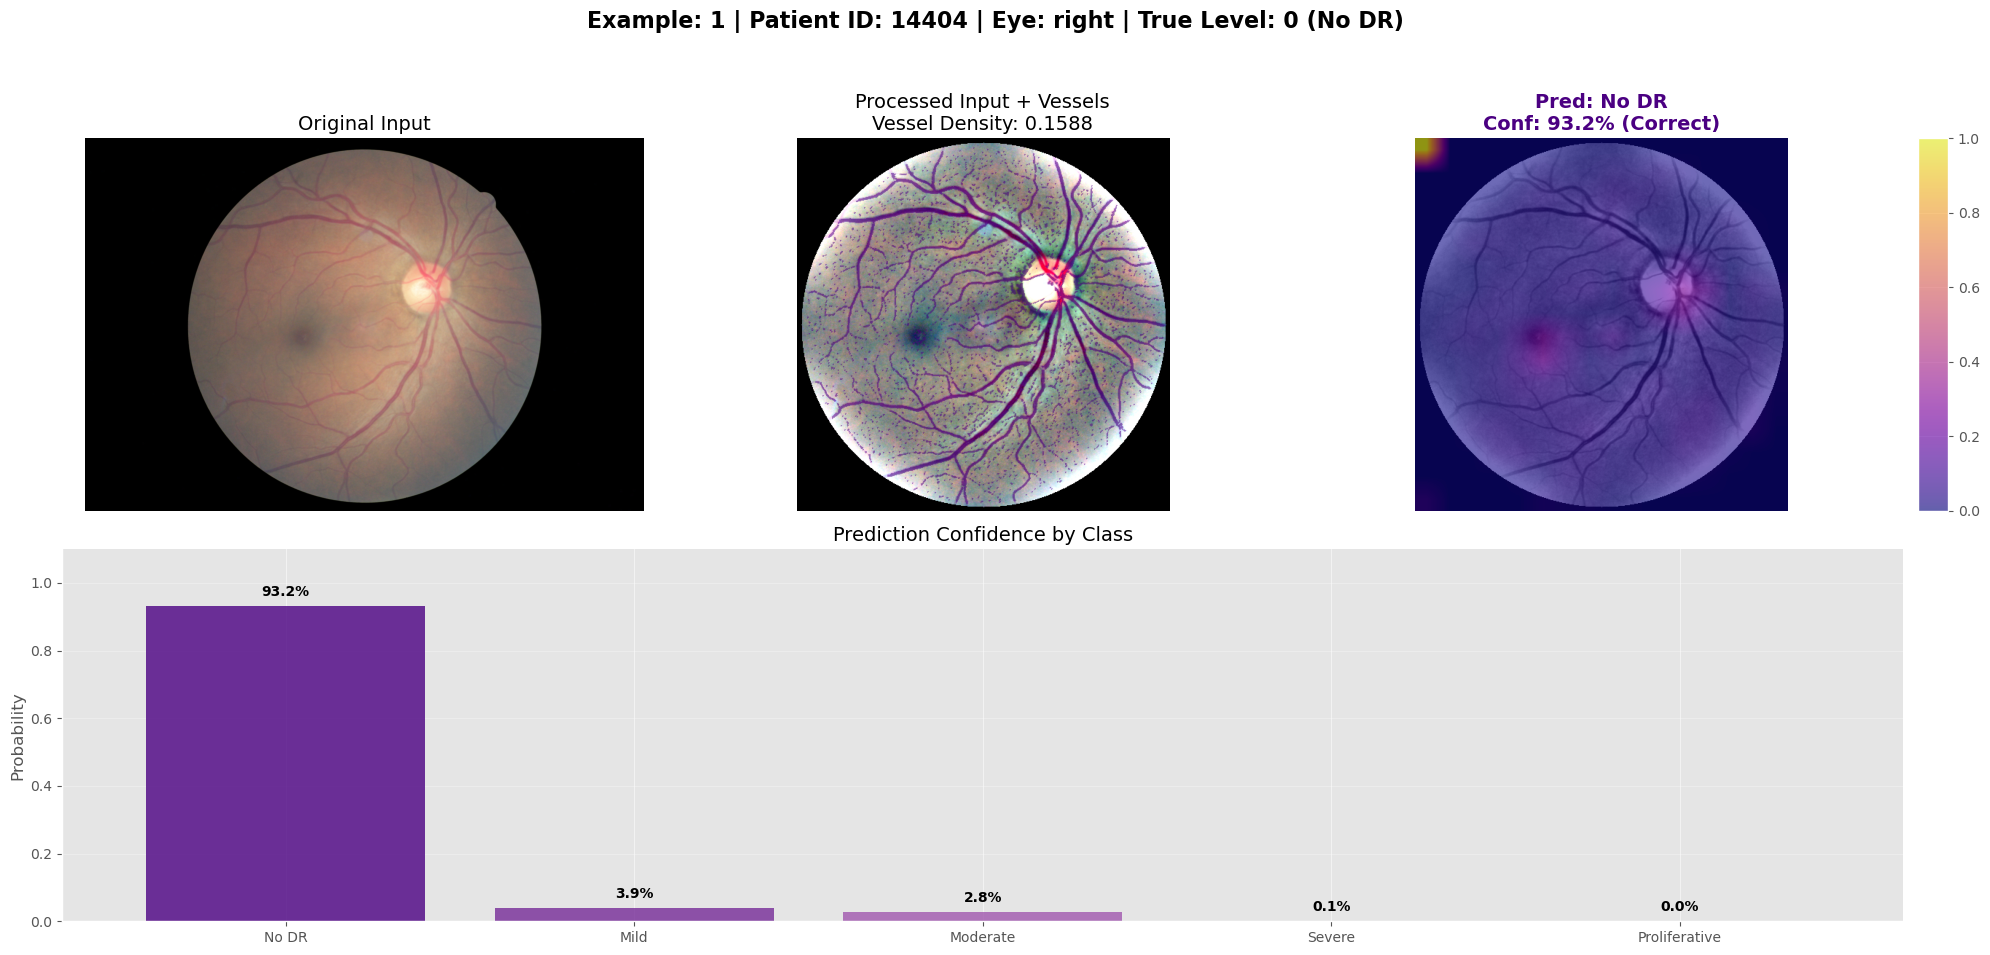

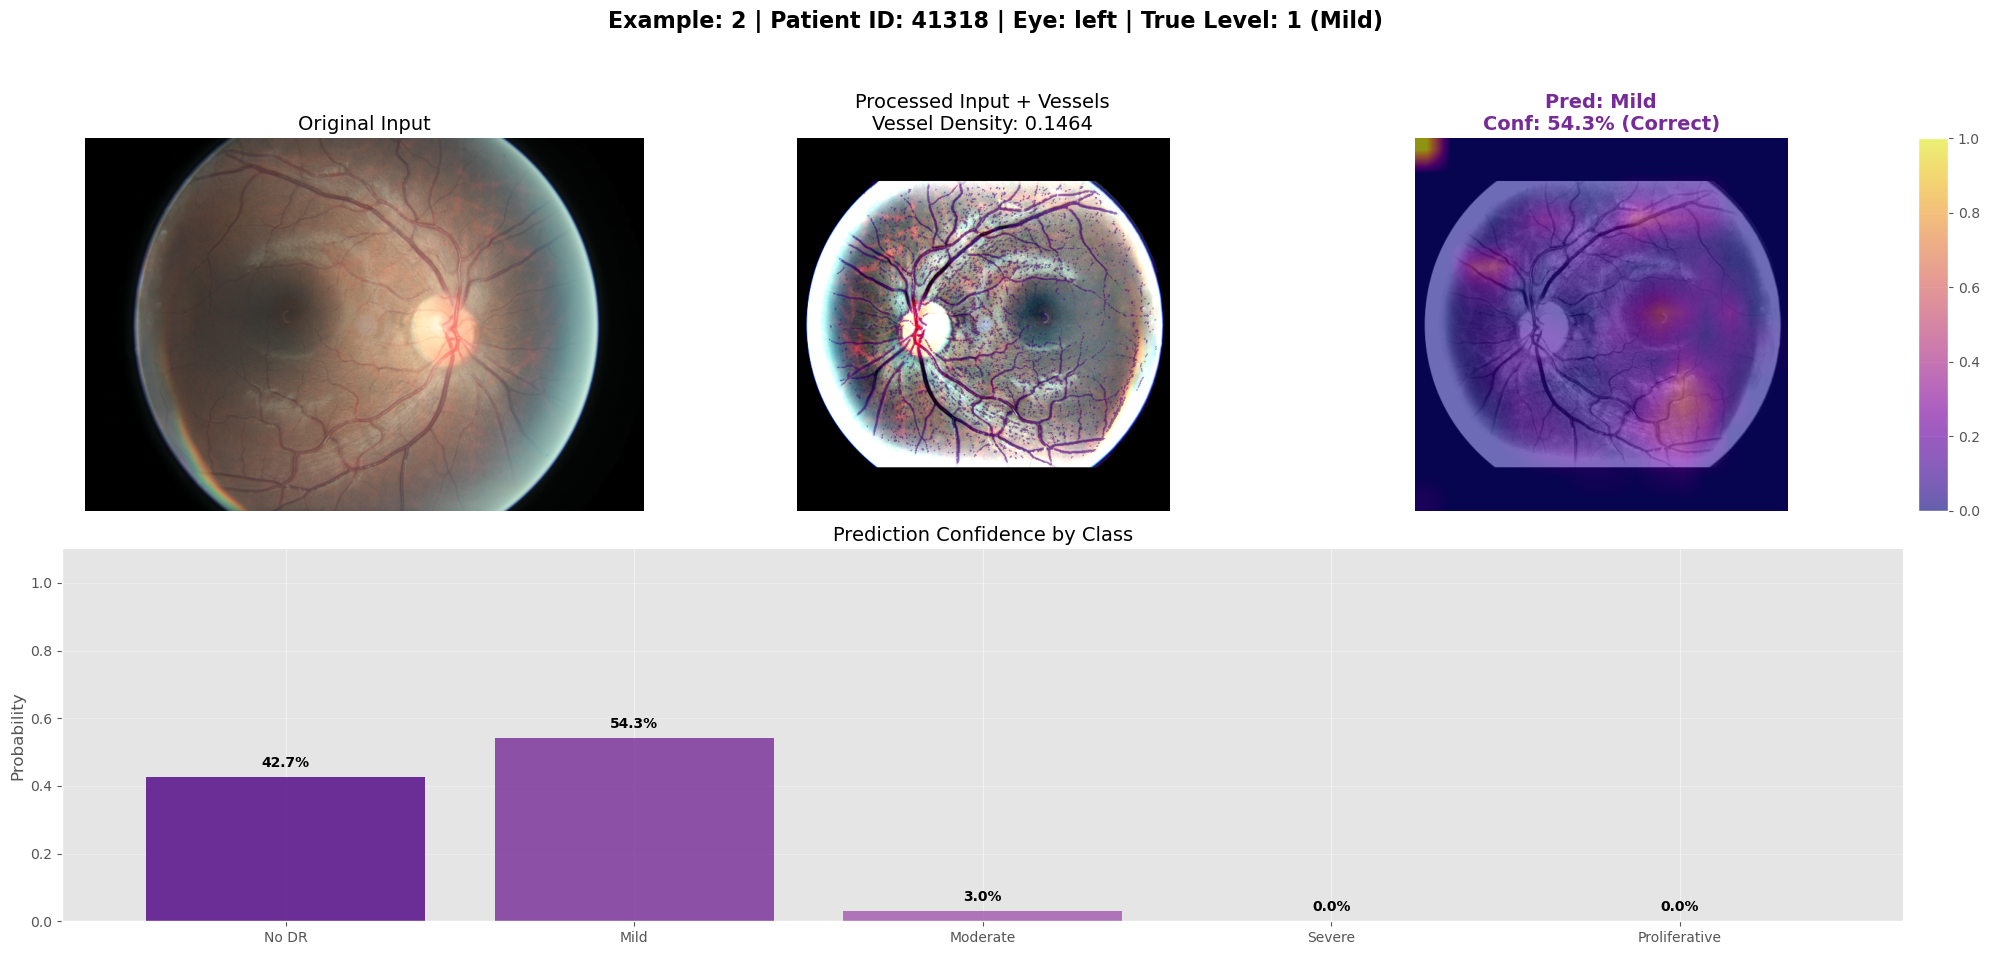

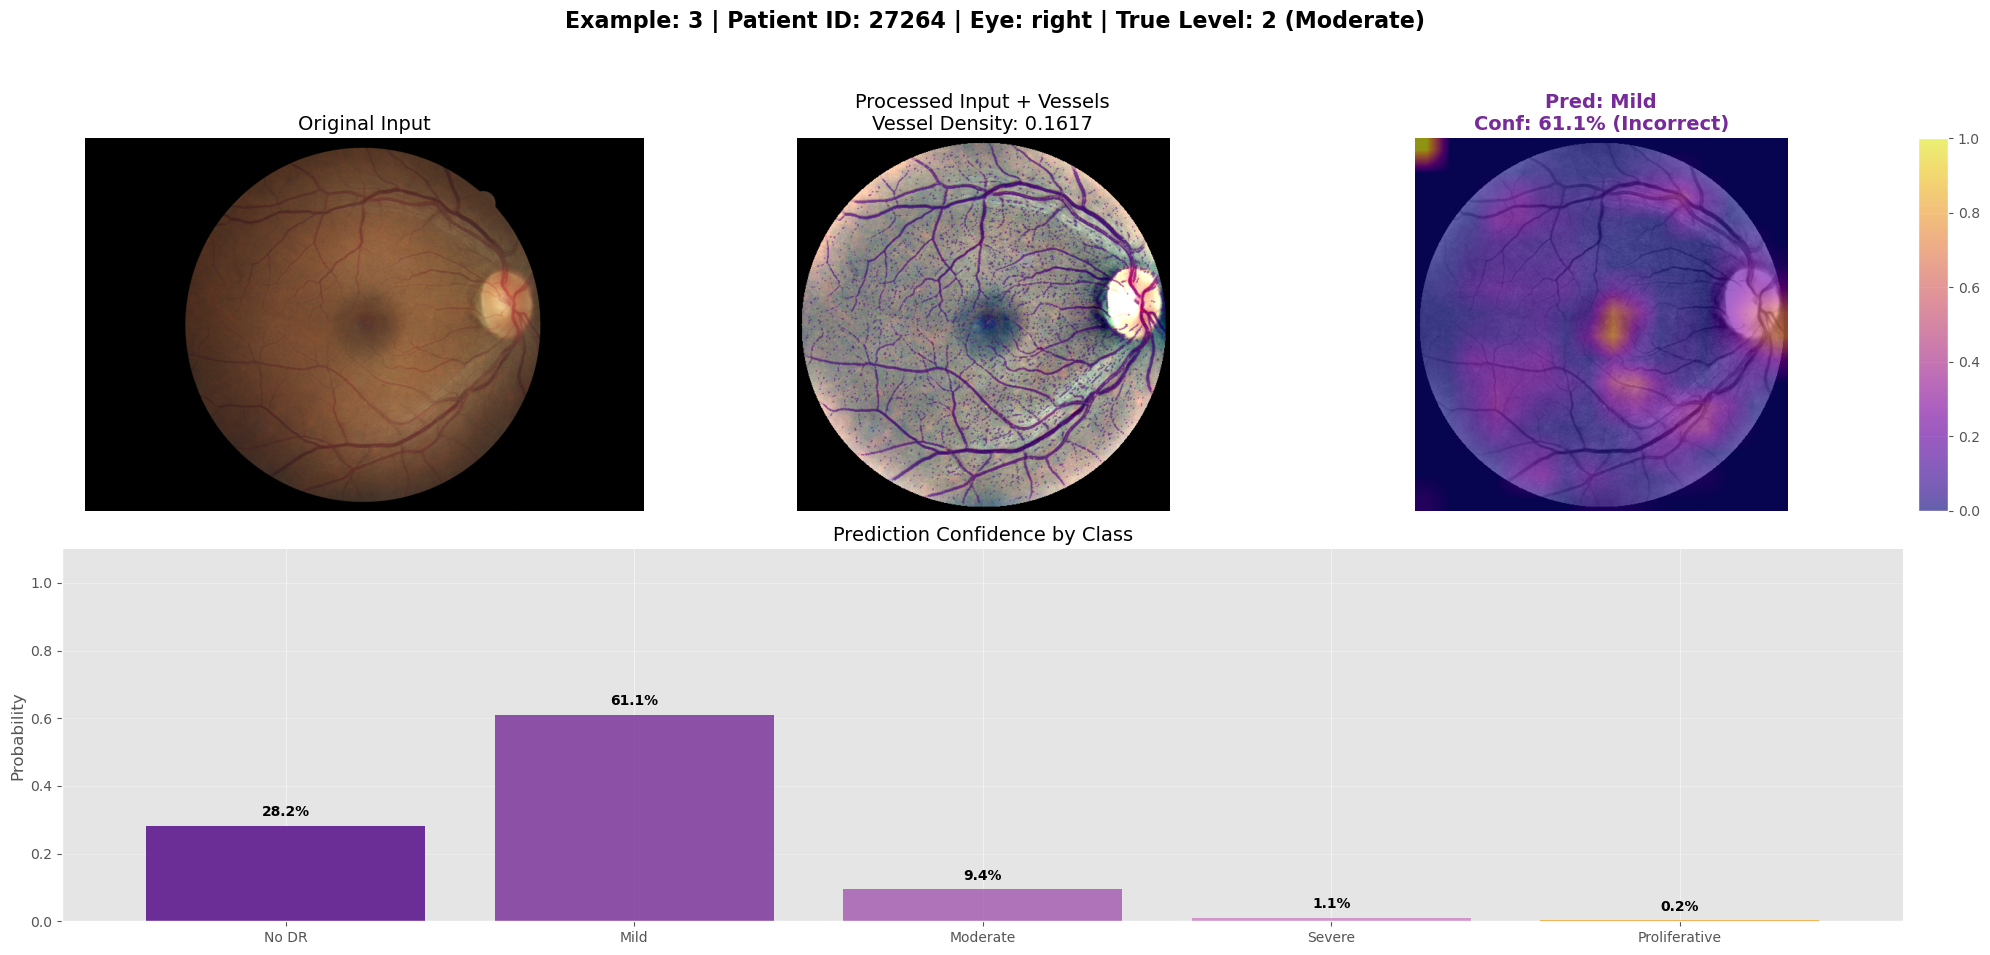

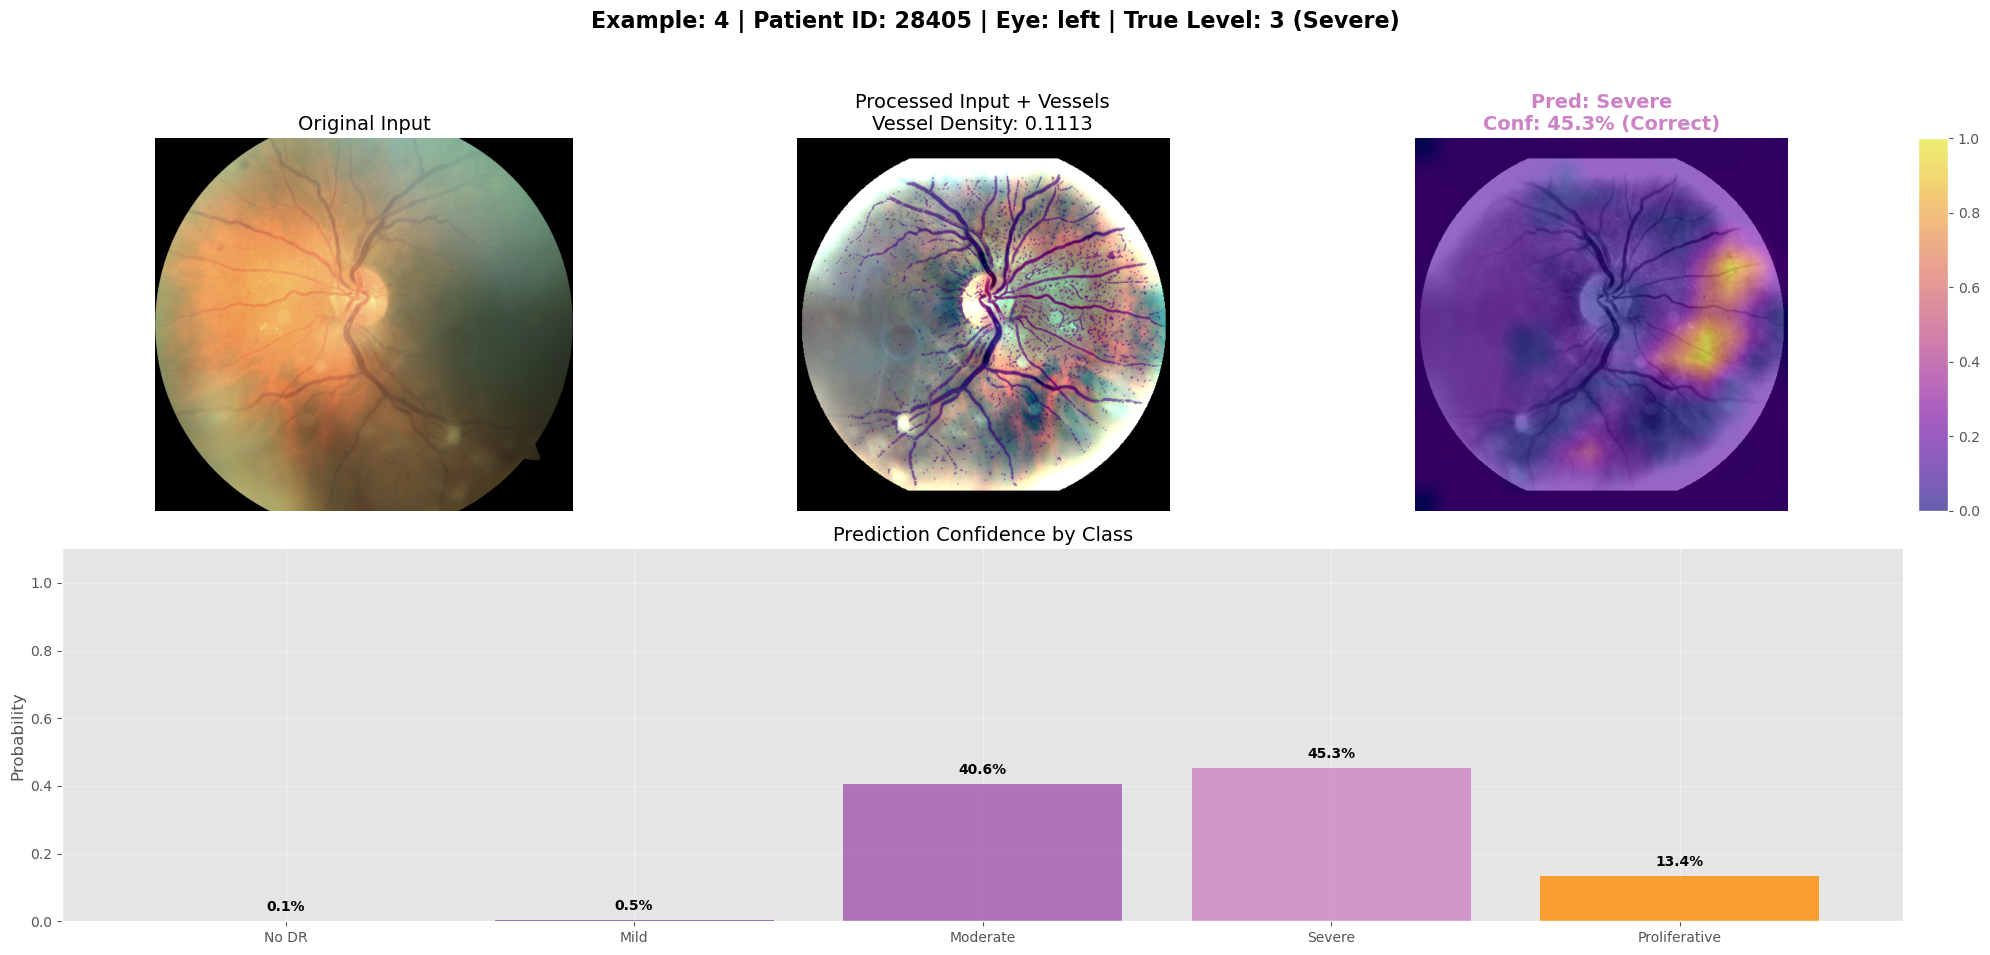

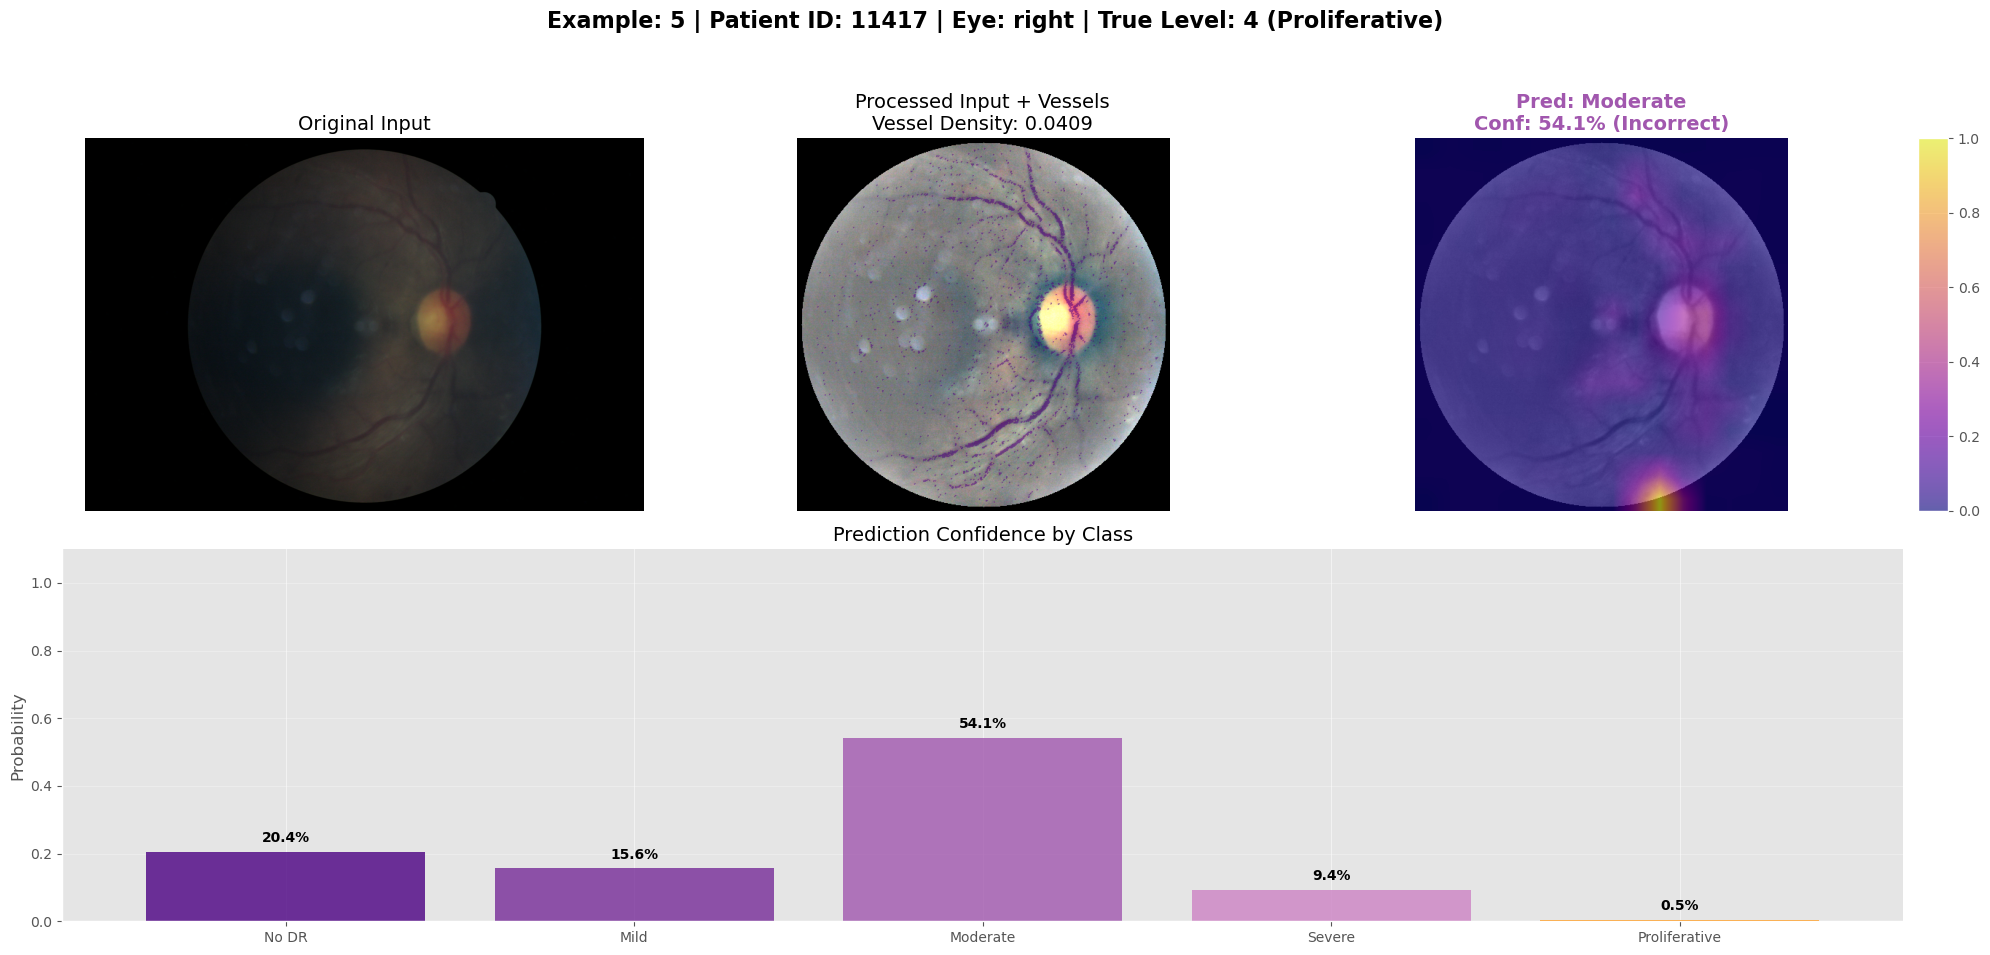

In [4]:
# 4. Run Inference on Multiple Examples

manifest_path = PROCESSED_DATA_DIR / "manifest.csv"
if manifest_path.exists():
    df = pd.read_csv(manifest_path)
    
    # Select one example from each class if available
    samples = []
    classes = [0, 1, 2, 3, 4] 
    
    for c in classes:
        class_samples = df[df['level'] == c]
        if not class_samples.empty:
            samples.append(class_samples.sample(1).iloc[0])
            
    print(f"Selected {len(samples)} examples for demonstration.")
    
    class_map = {0: "No DR", 1: "Mild", 2: "Moderate", 3: "Severe", 4: "Proliferative"}
    
    # Display all selected samples
    for i, sample in enumerate(samples):
        # Prepare Info for Suptitle
        info = {
            'Example': i+1,
            'Patient ID': sample['patient_id'],
            'Eye': sample['eye'],
            'True Level': f"{sample['level']} ({class_map[sample['level']]})"
        }
        
        try:
            run_inference_and_visualize(
                sample['path'], 
                true_label=class_map[sample['level']],
                eye_side=sample['eye'], # Pass explicitly
                patient_info=info
            )
        except Exception as e:
            print(f"Error processing image {sample['path']}: {e}")
        
        # Add some spacing between examples
        print("\n" * 2)

else:
    print("No manifest found.")

# 5. Production API Verification

Finally, we test the **FastAPI** serving layer directly within the notebook using `TestClient`. 
This simulates a real HTTP request to the deployed service (API) and verifies:
1.  Image upload via `multipart/form-data`.
2.  End-to-end inference execution.
3.  Response schema validation (Diagnosis + Confidence + Grad-CAM overlay).

INFO:src.app.main:Loading DR Detection Model...
INFO:src.app.predictor:Initializing Predictor on cuda...
INFO:src.app.predictor:Loading weights from C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\models\efficientnet_b3_best.pth
INFO:src.app.predictor:Grad-CAM initialized on layer: Conv2dNormActivation(
  (0): Conv2d(384, 1536, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1536, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)
INFO:src.app.main:Model loaded successfully.


TestClient initialized and lifespan started.
Model loaded successfully in app state.
Selected fresh random sample from manifest: C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\data\train\11590_left.jpeg (Level: 3 (Severe))
Sending POST request to /predict with image...


INFO:httpx:HTTP Request: POST http://testserver/predict "HTTP/1.1 200 OK"


--------------------------------------------------
API RESPONSE SUCCESS
Filename: sample.jpeg
Diagnosis: Severe
Confidence: 0.8706
Referral Advised: True
--------------------------------------------------


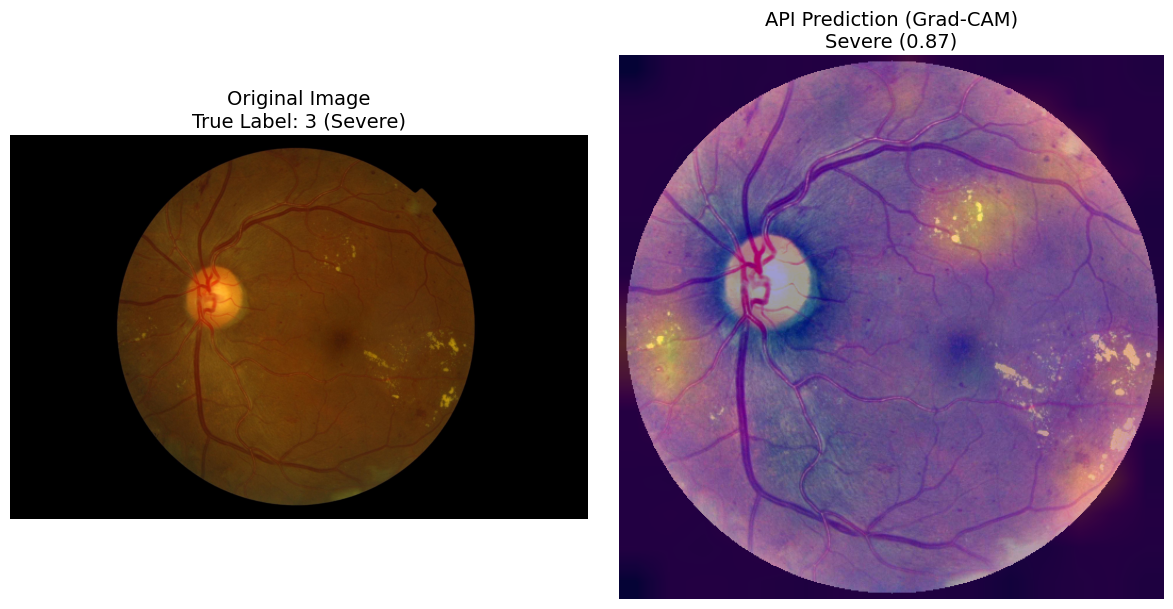

INFO:src.app.main:Model unloaded.


In [29]:
from fastapi.testclient import TestClient
from src.app.main import app, models
from PIL import Image
import io
import base64
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import random
import pandas as pd
from src.config import PROCESSED_DATA_DIR

# Use 'with TestClient(app) as client' to ensure lifespan events (startup) run correctly
try:
    with TestClient(app) as client:
        print("TestClient initialized and lifespan started.")
        
        # Verify model loaded
        if "predictor" in models:
            print("Model loaded successfully in app state.")
        else:
            print("WARNING: Model NOT found in app state after startup.")

        # 2. Select a Sample Image directly from the manifest to ensure variety
        sample_image_path = None
        true_label_desc = "Unknown"
        
        manifest_path = PROCESSED_DATA_DIR / "manifest.csv"
        
        if manifest_path.exists():
            df = pd.read_csv(manifest_path)
            # Filter for Proliferative (4) or Severe (3) cases
            severe_df = df[df['level'] >= 3]
            
            if not severe_df.empty:
                # Pick a random sample from the FULL severe dataset
                selected_row = severe_df.sample(1).iloc[0]
                sample_image_path = selected_row['path']
                true_label_val = selected_row['level']
                class_map_local = {0: "No DR", 1: "Mild", 2: "Moderate", 3: "Severe", 4: "Proliferative"}
                true_label_desc = f"{true_label_val} ({class_map_local.get(true_label_val, 'Unknown')})"
                print(f"Selected fresh random sample from manifest: {sample_image_path} (Level: {true_label_desc})")
            else:
                print("No severe cases found in manifest.")
        
        # Fallback to the previous logic if manifest fails or finding images fails
        if not sample_image_path or not Path(sample_image_path).exists():
            print("Fallback: Using notebook samples or file search...")
             # ... (previous search logic fallback could go here, but for now we rely on manifest)
            if 'samples' in locals() and len(samples) > 0:
                 selected_sample = samples[-1] # Fallback to whatever is in samples
                 sample_image_path = selected_sample['path']
                 true_label_val = selected_sample['level']

        if sample_image_path and Path(sample_image_path).exists():
            # 3. Send POST request
            print(f"Sending POST request to /predict with image...")
            try:
                with open(sample_image_path, "rb") as f:
                    response = client.post(
                        "/predict",
                        files={"file": ("sample.jpeg", f, "image/jpeg")}
                    )

                # 4. Handle Response
                if response.status_code == 200:
                    result = response.json()
                    
                    print("-" * 50)
                    print("API RESPONSE SUCCESS")
                    print(f"Filename: {result.get('filename')}")
                    print(f"Diagnosis: {result['diagnosis']}")
                    print(f"Confidence: {result['confidence']:.4f}")
                    print(f"Referral Advised: {result['referral_advised']}")
                    print("-" * 50)
                    
                    # 5. Decode and Display Grad-CAM
                    if result.get("gradcam_base64"):
                        img_data = base64.b64decode(result["gradcam_base64"])
                        gradcam_img = Image.open(io.BytesIO(img_data))
                        original_img = Image.open(sample_image_path)
                        
                        fig, axes = plt.subplots(1, 2, figsize=(12, 6))
                        
                        # Plot Original
                        axes[0].imshow(original_img)
                        axes[0].set_title(f"Original Image\nTrue Label: {true_label_desc}")
                        axes[0].axis('off')

                        # Plot Grad-CAM Result
                        axes[1].imshow(gradcam_img)
                        axes[1].set_title(f"API Prediction (Grad-CAM)\n{result['diagnosis']} ({result['confidence']:.2f})")
                        axes[1].axis('off')
                        
                        plt.tight_layout()
                        plt.show()
                        
                else:
                    print(f"API Request Failed: {response.status_code}")
                    print(response.json())
            except Exception as e:
                print(f"Error during request: {e}")
                
        else:
            print("No sample image found to test API.")

except Exception as e:
    print(f"TestClient failed to start: {e}")